Training data shape: (40000, 3072)
Testing data shape: (10000, 3072)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 402,250 (1.53 MB)

 Trainable params: 402,250 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.2951 - loss: 1.9325 - val_accuracy: 0.3335 - val_loss: 1.8607
Epoch 2/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.3682 - loss: 1.7569 - val_accuracy: 0.3865 - val_loss: 1.7163
Epoch 3/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.3944 - loss: 1.6875 - val_accuracy: 0.3985 - val_loss: 1.6839
Epoch 4/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.4131 - loss: 1.6365 - val_accuracy: 0.4055 - val_loss: 1.6752
Epoch 5/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4249 - loss: 1.6014 - val_accuracy: 0.4132 - val_loss: 1.6300
Epoch 6/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.4347 - loss: 1.5746 - val_accuracy: 0.4410 - val_loss: 1.5736
Epoch 7/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4463 - loss: 1.5481 - val_accuracy: 0.4353 - val_loss: 1.5863
Epoch 8/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.4543 - 

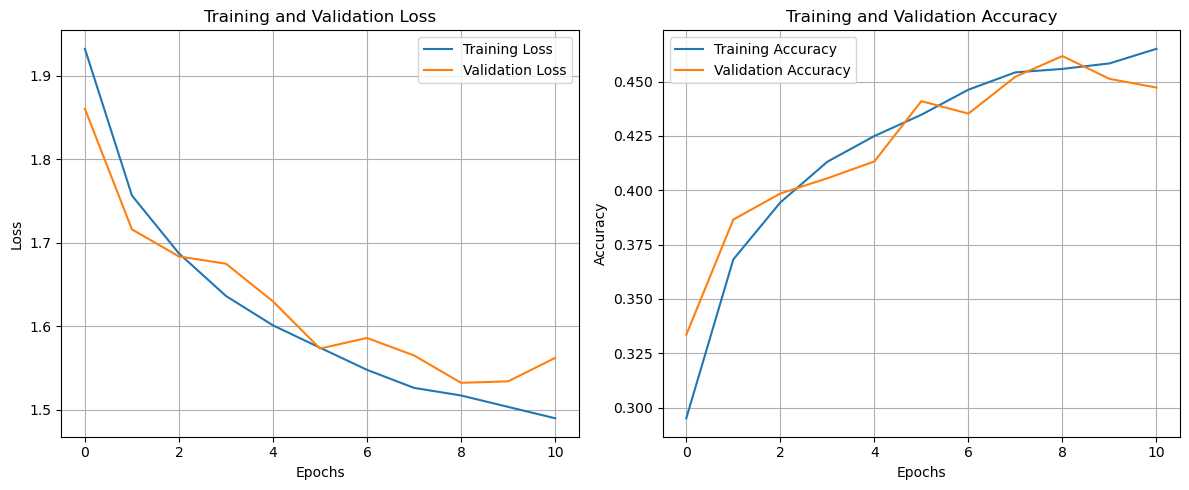

In [1]:

# EXPERIMENT 1C
# Feedforward Neural Network (FNN) for CIFAR-10
# Using Keras and TensorFlow

# a. Import necessary packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split


# b. Load training and testing data

# Load single CSV dataset

data = pd.read_csv("cifar-10.csv")

# Separate features and labels

X = data.drop("label", axis=1).values
y = data["label"].values

# Convert data type

X = X.astype("float32")

# Normalize pixel values between 0 and 1

X = X / 255.0

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


# c. Define FNN architecture using Keras

model = keras.Sequential([
    layers.Input(shape=(3072,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Display model architecture

model.summary()


# Compile the model using Adam optimizer

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# d. Train the model

history = model.fit(
    X_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


# e. Evaluate the network

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")


# f. Plot training loss and accuracy

plt.figure(figsize=(12, 5))

# Training and validation loss

plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


# Training and validation accuracy

plt.subplot(1, 2, 2)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
